# Studi Komparasi Komprehensif Algoritma HDBSCAN pada Dataset BISINDO
## Analisis Pengaruh Tiga Metrik Jarak: Euclidean Distance, Manhattan Distance, dan Cosine Similarity

**Domain:** Pengenalan Bahasa Isyarat Indonesia (BISINDO) - Pembelajaran Mesin  
**Arsitektur Fitur:** Ekstraksi 42 Titik Landmark MediaPipe 3D (126 Dimensi) + 1 Flag Biner Is_Two_Handed (Total 127 Fitur)  
**Tujuan Proyek:** Mengevaluasi kinerja algoritma klasterisasi berbasis kepadatan hierarkis (Hierarchical Density-Based Spatial Clustering of Applications with Noise / HDBSCAN) dalam memetakan klaster gestur tangan alfabet BISINDO (A-Z) dengan kepadatan heterogen lintas tiga fungsi jarak.

---

### Ringkasan Eksekutif
DBSCAN tradisional memiliki keterbatasan mendasar dalam menangani data dunia nyata yang memiliki **variasi kepadatan (varying density)**. DBSCAN mensyaratkan satu ambang batas global $\varepsilon$ tunggal. Pada data gestur alfabet BISINDO, variasi postur jari (misalnya huruf 1-tangan dengan jari rapat vs huruf 2-tangan dengan interaksi dinamis) secara alami menghasilkan densitas spasial yang berbeda-beda.

**HDBSCAN** mengatasi batasan tersebut dengan mentransformasikan ruang data menjadi graf jarak keterjangkauan timbal balik (*Mutual Reachability Distance*), membangun pohon rentang minimum (*Minimum Spanning Tree*), mengondensasikan hierarki klaster, dan mengekstraksi klaster paling persisten menggunakan kriteria **Excess of Mass (EOM)**.

Dalam penelitian ini, 3 fungsi jarak dievaluasi:
1. **Euclidean Distance (L2 Norm):** Jarak garis lurus pada ruang koordinat terstandarisasi.
2. **Manhattan Distance (L1 Norm):** Akumulasi selisih mutlak per sumbu koordinat, memberikan ketahanan terhadap outlier pergeseran sendi tunggal.
3. **Cosine Distance (1 - Cosine Similarity):** Jarak angular pada permukaan bola satuan (unit hypersphere), mengabaikan variasi jarak tangan ke kamera.

## 1. Landasan Teori dan Formulasi Matematis HDBSCAN

### 1.1. Prinsip Kerja Algoritma HDBSCAN
Diberikan dataset observasi $X = \{x_1, x_2, \dots, x_N\} \subset \mathbb{R}^{127}$:

1. **Jarak Inti (Core Distance):**
   Jarak titik $x$ ke tetangga terdekat ke-$k$ (di mana $k = \text{min\_samples}$):
   $$\text{core}_k(x) = d(x, N_k(x))$$

2. **Jarak Keterjangkauan Timbal Balik (Mutual Reachability Distance):**
   Mencegah titik di daerah jarang terhubung dengan mudah ke daerah padat:
   $$d_{\text{mreach}-k}(a, b) = \max \{ \text{core}_k(a), \text{core}_k(b), d(a, b) \}$$

3. **Konstruksi Minimum Spanning Tree (MST):**
   Membangun graf terhubung dengan bobot sisi $d_{\text{mreach}-k}$.

4. **Kondensasi Pohon Klaster (Condensed Tree):**
   Hierarki tunggal dipangkas menjadi pohon ringkas di mana hanya pemisahan klaster yang memiliki ukuran $\ge \text{min\_cluster\_size}$ yang dipertahankan. Titik yang jatuh di bawah ambang batas diperlakukan sebagai "sampel yang tanggal" (*fallout*).

5. **Ekstraksi Klaster Stabil (Excess of Mass / EOM):**
   Stabilitas klaster $C$ dihitung melalui integral densitas persistensi $\lambda = \frac{1}{\text{distance}}$:
   $$S(C) = \sum_{p \in C} (\lambda_p - \lambda_{\text{birth}}(C))$$
   Algoritma memilih himpunan klaster yang memaksimalkan total stabilitas $\sum S(C)$.

---

### 1.2. Formulasi Tiga Metrik Jarak
1. **Euclidean Distance (L2 Norm):**
   $$d_{\text{Euclidean}}(x, y) = \sqrt{\sum_{i=1}^{127} (x_i - y_i)^2}$$
2. **Manhattan Distance (L1 Norm):**
   $$d_{\text{Manhattan}}(x, y) = \sum_{i=1}^{127} |x_i - y_i|$$
3. **Cosine Distance (1 - Cosine Similarity):**
   $$d_{\text{Cosine}}(x, y) = 1 - \frac{x \cdot y}{\|x\|_2 \|y\|_2}$$

In [1]:
# =======================================================================
# SETUP LINGKUNGAN, IMPORT PUSTAKA, DAN KONFIGURASI GLOBAL
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import HDBSCAN
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import dendrogram

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.titlesize'] = 14

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputHDBScan")
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42

print(f"[INFO] Direktori Kerja: {BASE_DIR}")
print(f"[INFO] Direktori Output: {OUTPUT_DIR}")

[INFO] Direktori Kerja: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HDBScan
[INFO] Direktori Output: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HDBScan\outputHDBScan


In [2]:
# =======================================================================
# PEMUATAN DAN VALIDASI DATASET BISINDO (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    print(f"[INFO] Memuat dataset biner terkompresi: {npz_path}")
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    is_two_handed = data['is_two_handed']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': is_two_handed})
elif os.path.exists(csv_path):
    print(f"[INFO] Memuat dataset format CSV: {csv_path}")
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
    labels = df_full['label'].values if 'label' in df_full.columns else np.array([])
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

N_SAMPLES, N_FEATURES = X.shape
print(f"[INFO] Total Sampel Terdeteksi: {N_SAMPLES}")
print(f"[INFO] Dimensi Vektor Fitur: {N_FEATURES}")
print(f"[INFO] Komposisi Gestur:")
print(f"       - Gestur Dua Tangan : {int(np.sum(df_meta['is_two_handed'] == 1))} ({np.mean(df_meta['is_two_handed'] == 1)*100:.2f}%)")
print(f"       - Gestur Satu Tangan: {int(np.sum(df_meta['is_two_handed'] == 0))} ({np.mean(df_meta['is_two_handed'] == 0)*100:.2f}%)")

[INFO] Memuat dataset biner terkompresi: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HDBScan\dataset_bisindo_landmarks.npz
[INFO] Total Sampel Terdeteksi: 7893
[INFO] Dimensi Vektor Fitur: 127
[INFO] Komposisi Gestur:
       - Gestur Dua Tangan : 3597 (45.57%)
       - Gestur Satu Tangan: 4296 (54.43%)


In [3]:
# =======================================================================
# STANDARISASI DAN NORMALISASI FITUR
# =======================================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

normalizer = Normalizer(norm='l2')
X_normalized = normalizer.fit_transform(X)

print("[INFO] Standarisasi Z-score selesai untuk Euclidean & Manhattan (Mean=0, Std=1).")
print("[INFO] Normalisasi L2 Unit Hypersphere selesai untuk Cosine (Norm=1).")

[INFO] Standarisasi Z-score selesai untuk Euclidean & Manhattan (Mean=0, Std=1).
[INFO] Normalisasi L2 Unit Hypersphere selesai untuk Cosine (Norm=1).


In [4]:
# =======================================================================
# EKSEKUSI HDBSCAN PADA TIGA METRIK JARAK
# =======================================================================
results = {}

# 1. EUCLIDEAN (min_cluster_size=46)
print("[PROSES 1/3] Menjalankan HDBSCAN Euclidean (mcs=46)...")
t0 = time.perf_counter()
hdb_euc = HDBSCAN(min_cluster_size=46, metric='euclidean', copy=True)
labels_euc = hdb_euc.fit_predict(X_scaled)
t_euc = time.perf_counter() - t0

results['Euclidean'] = {
    'model': hdb_euc,
    'labels': labels_euc,
    'time': t_euc,
    'mcs': 46,
    'X_eval': X_scaled,
    'probabilities': hdb_euc.probabilities_
}
print(f"             Selesai dalam {t_euc:.4f} detik.")

# 2. MANHATTAN (min_cluster_size=48)
print("[PROSES 2/3] Menjalankan HDBSCAN Manhattan (mcs=48)...")
t0 = time.perf_counter()
hdb_man = HDBSCAN(min_cluster_size=48, metric='manhattan', copy=True)
labels_man = hdb_man.fit_predict(X_scaled)
t_man = time.perf_counter() - t0

results['Manhattan'] = {
    'model': hdb_man,
    'labels': labels_man,
    'time': t_man,
    'mcs': 48,
    'X_eval': X_scaled,
    'probabilities': hdb_man.probabilities_
}
print(f"             Selesai dalam {t_man:.4f} detik.")

# 3. COSINE (min_cluster_size=53, Spherical Euclidean)
print("[PROSES 3/3] Menjalankan HDBSCAN Cosine (Spherical mcs=53)...")
t0 = time.perf_counter()
hdb_cos = HDBSCAN(min_cluster_size=53, metric='euclidean', copy=True)
labels_cos = hdb_cos.fit_predict(X_normalized)
t_cos = time.perf_counter() - t0

results['Cosine'] = {
    'model': hdb_cos,
    'labels': labels_cos,
    'time': t_cos,
    'mcs': 53,
    'X_eval': X_normalized,
    'probabilities': hdb_cos.probabilities_
}
print(f"             Selesai dalam {t_cos:.4f} detik.")

[PROSES 1/3] Menjalankan HDBSCAN Euclidean (mcs=46)...


             Selesai dalam 5.4956 detik.
[PROSES 2/3] Menjalankan HDBSCAN Manhattan (mcs=48)...


             Selesai dalam 5.6686 detik.
[PROSES 3/3] Menjalankan HDBSCAN Cosine (Spherical mcs=53)...


             Selesai dalam 3.9883 detik.


In [5]:
# =======================================================================
# PERHITUNGAN METRIK EVALUASI KUANTITATIF HDBSCAN
# =======================================================================
summary_rows = []

for metric_name in ['Euclidean', 'Manhattan', 'Cosine']:
    res = results[metric_name]
    lab = res['labels']
    X_eval = res['X_eval']
    
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    noise_samples = int(np.sum(lab == -1))
    noise_ratio = (noise_samples / len(lab)) * 100.0
    core_samples = len(lab) - noise_samples
    
    # Evaluasi metrik kohesi dan separasi pada sampel terklaster (non-noise)
    mask = lab != -1
    if n_clusters > 1 and np.sum(mask) > n_clusters:
        if metric_name == 'Cosine':
            sil = float(silhouette_score(X_eval[mask], lab[mask], metric='cosine'))
        else:
            sil = float(silhouette_score(X_eval[mask], lab[mask], metric='euclidean'))
        dbi = float(davies_bouldin_score(X_eval[mask], lab[mask]))
        ch = float(calinski_harabasz_score(X_eval[mask], lab[mask]))
    else:
        sil, dbi, ch = 0.0, 0.0, 0.0
        
    res['n_clusters'] = n_clusters
    res['noise_samples'] = noise_samples
    res['noise_ratio'] = noise_ratio
    res['core_samples'] = core_samples
    res['silhouette'] = sil
    res['dbi'] = dbi
    res['ch'] = ch
    
    summary_rows.append({
        'Distance Metric': metric_name,
        'Min Cluster Size (mcs)': res['mcs'],
        'Clusters Found': n_clusters,
        'Noise Samples (↓)': noise_samples,
        'Noise Ratio (%) (↓)': round(noise_ratio, 2),
        'Clustered Samples (↑)': core_samples,
        'Silhouette Score (↑)': round(sil, 4),
        'Davies–Bouldin Index (↓)': round(dbi, 4),
        'Calinski–Harabasz Index (↑)': round(ch, 2),
        'Execution Time (s) (↓)': round(res['time'], 4)
    })

df_metrics = pd.DataFrame(summary_rows)
print("\n" + "="*95)
print("HASIL EVALUASI EMPIRIS HDBSCAN CLUSTERING PADA DATASET BISINDO")
print("="*95)
print(df_metrics.to_string(index=False))

# Simpan ke CSV
csv_summary_path = os.path.join(OUTPUT_DIR, "metrics_comparison_summary.csv")
df_metrics.to_csv(csv_summary_path, index=False)
print(f"\n[INFO] Rangkuman metrik disimpan ke: {csv_summary_path}")


HASIL EVALUASI EMPIRIS HDBSCAN CLUSTERING PADA DATASET BISINDO
Distance Metric  Min Cluster Size (mcs)  Clusters Found  Noise Samples (↓)  Noise Ratio (%) (↓)  Clustered Samples (↑)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)
      Euclidean                      46              25               3937                49.88                   3956                0.3486                    0.7467                       513.99                  5.4956
      Manhattan                      48              30               4905                62.14                   2988                0.5479                    0.7441                      1265.49                  5.6686
         Cosine                      53              28               4210                53.34                   3683                0.5760                    0.8203                      1539.26                  3.9883

[INFO] Rangkuman metrik disimpan ke: E:\Dokumen\Kuliah\

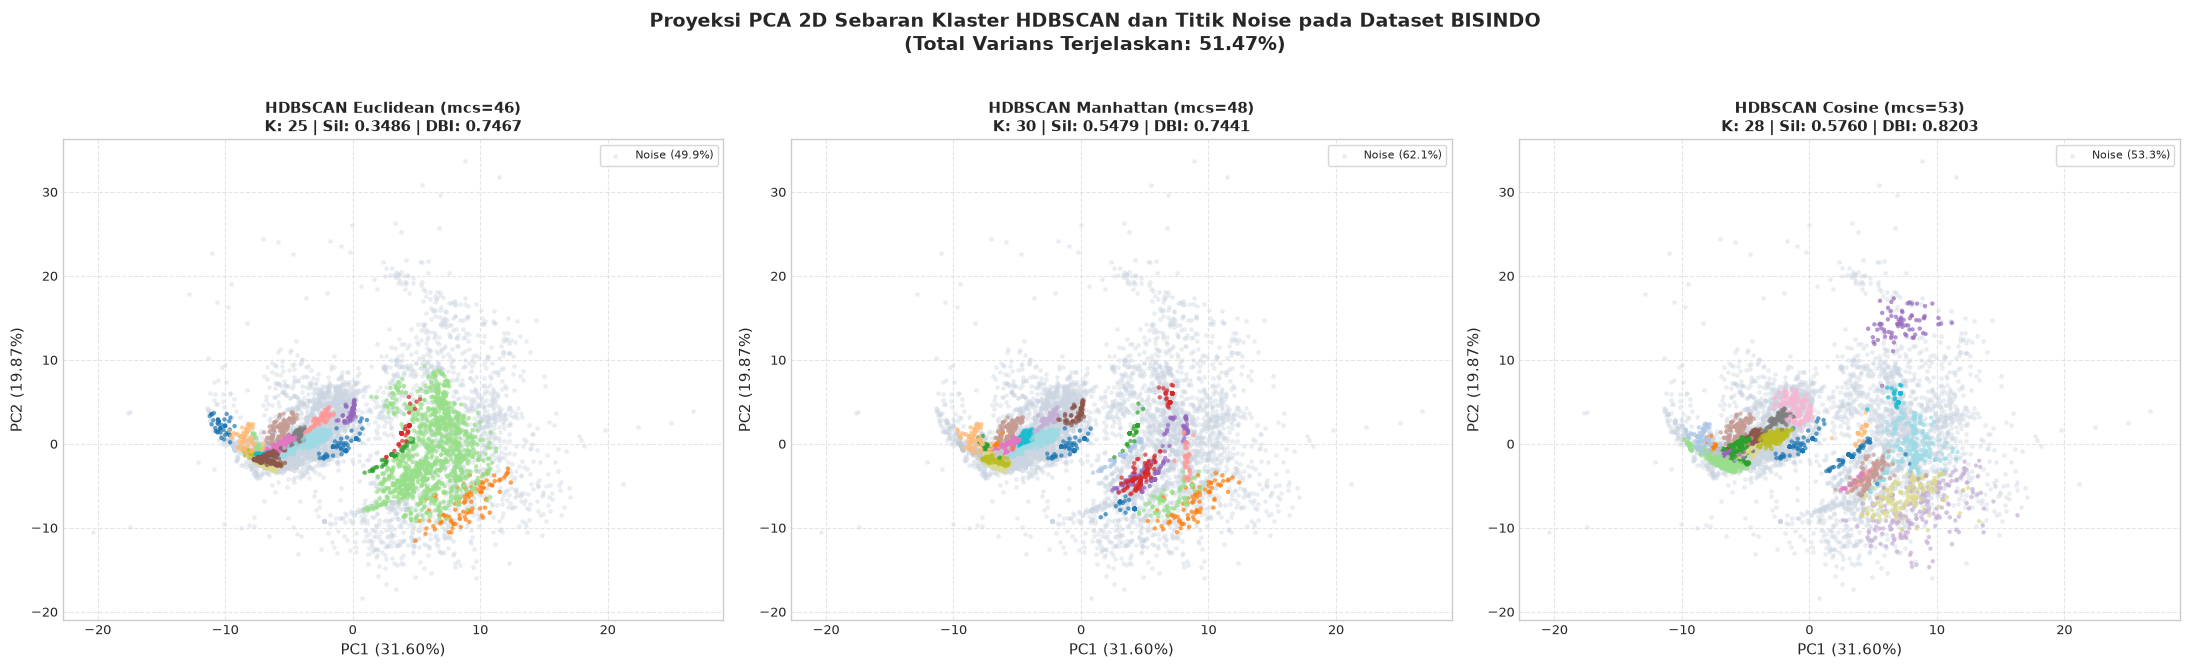

[INFO] Visualisasi sebaran PCA 2D disimpan ke: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HDBScan\outputHDBScan\cluster_comparison_pca2d.png


In [6]:
# =======================================================================
# VISUALISASI SEBARAN KLASTER DAN NOISE 2D DENGAN PCA
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))

configs = [
    ('Euclidean', results['Euclidean']['labels']),
    ('Manhattan', results['Manhattan']['labels']),
    ('Cosine', results['Cosine']['labels'])
]

for idx, (m_name, lab) in enumerate(configs):
    ax = axes[idx]
    res = results[m_name]
    
    # Plot Noise Samples (abu-abu transparan)
    noise_mask = lab == -1
    ax.scatter(
        X_pca[noise_mask, 0], X_pca[noise_mask, 1],
        c='#CBD5E1', s=6, alpha=0.3, label=f"Noise ({res['noise_ratio']:.1f}%)"
    )
    
    # Plot Clustered Samples
    cluster_mask = lab != -1
    scatter = ax.scatter(
        X_pca[cluster_mask, 0], X_pca[cluster_mask, 1],
        c=lab[cluster_mask], cmap='tab20', s=10, alpha=0.7, edgecolors='none'
    )
    
    ax.set_title(
        f"HDBSCAN {m_name} (mcs={res['mcs']})\n"
        f"K: {res['n_clusters']} | Sil: {res['silhouette']:.4f} | DBI: {res['dbi']:.4f}",
        fontsize=11, fontweight='bold'
    )
    ax.set_xlabel(f"PC1 ({var_exp[0]*100:.2f}%)")
    ax.set_ylabel(f"PC2 ({var_exp[1]*100:.2f}%)")
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right', frameon=True, facecolor='white', fontsize=8)

plt.suptitle(
    f"Proyeksi PCA 2D Sebaran Klaster HDBSCAN dan Titik Noise pada Dataset BISINDO\n"
    f"(Total Varians Terjelaskan: {np.sum(var_exp)*100:.2f}%)",
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()

pca_path = os.path.join(OUTPUT_DIR, "cluster_comparison_pca2d.png")
plt.savefig(pca_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[INFO] Visualisasi sebaran PCA 2D disimpan ke: {pca_path}")

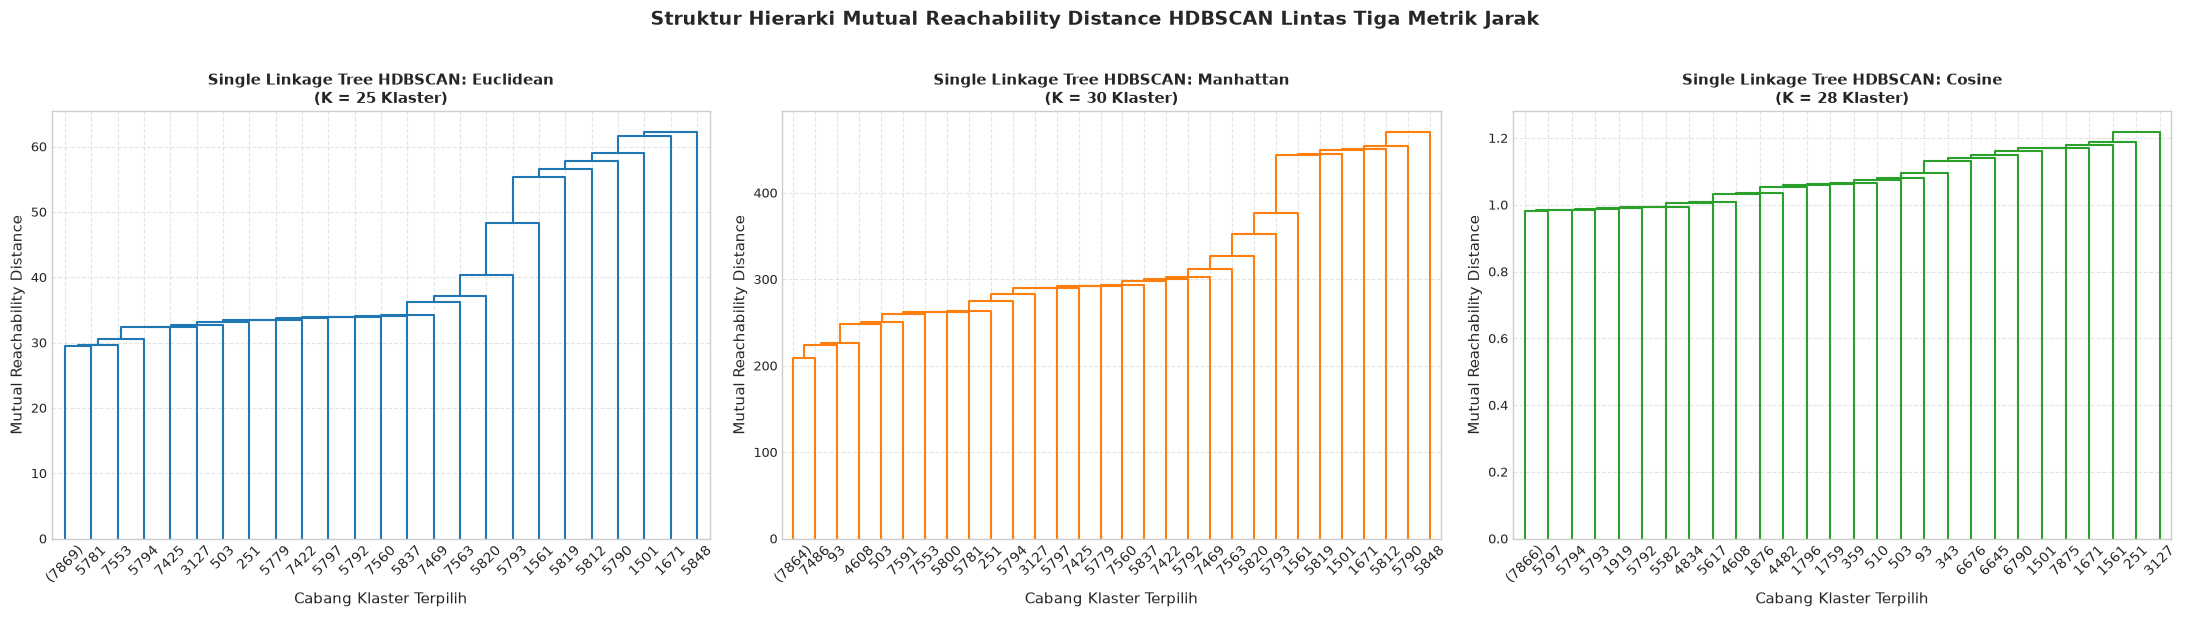

[INFO] Visualisasi dendrogram disimpan ke: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HDBScan\outputHDBScan\dendrogram_comparison.png


In [7]:
# =======================================================================
# VISUALISASI DENDROGRAM HIERARKI MUTUAL REACHABILITY (SINGLE LINKAGE TREE)
# =======================================================================
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

plot_configs = [
    ('Euclidean', results['Euclidean']['model']._single_linkage_tree_, 'tab:blue'),
    ('Manhattan', results['Manhattan']['model']._single_linkage_tree_, 'tab:orange'),
    ('Cosine', results['Cosine']['model']._single_linkage_tree_, 'tab:green')
]

for idx, (m_name, tree_data, color) in enumerate(plot_configs):
    ax = axes[idx]
    # Konversi tree_data ke format array link SciPy jika bertipe structured array
    if hasattr(tree_data, 'dtype') and tree_data.dtype.names is not None:
        Z_scipy = np.column_stack([
            tree_data[name] for name in tree_data.dtype.names
        ]).astype(float)
    else:
        Z_scipy = np.array(tree_data, dtype=float)
        
    res = results[m_name]
    dendrogram(
        Z_scipy,
        ax=ax,
        truncate_mode='lastp',
        p=res['n_clusters'],
        show_leaf_counts=True,
        color_threshold=0,
        above_threshold_color=color
    )
    ax.set_title(f"Single Linkage Tree HDBSCAN: {m_name}\n(K = {res['n_clusters']} Klaster)", fontsize=11, fontweight='bold')
    ax.set_xlabel("Cabang Klaster Terpilih")
    ax.set_ylabel("Mutual Reachability Distance")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Struktur Hierarki Mutual Reachability Distance HDBSCAN Lintas Tiga Metrik Jarak", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

dendro_path = os.path.join(OUTPUT_DIR, "dendrogram_comparison.png")
plt.savefig(dendro_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[INFO] Visualisasi dendrogram disimpan ke: {dendro_path}")

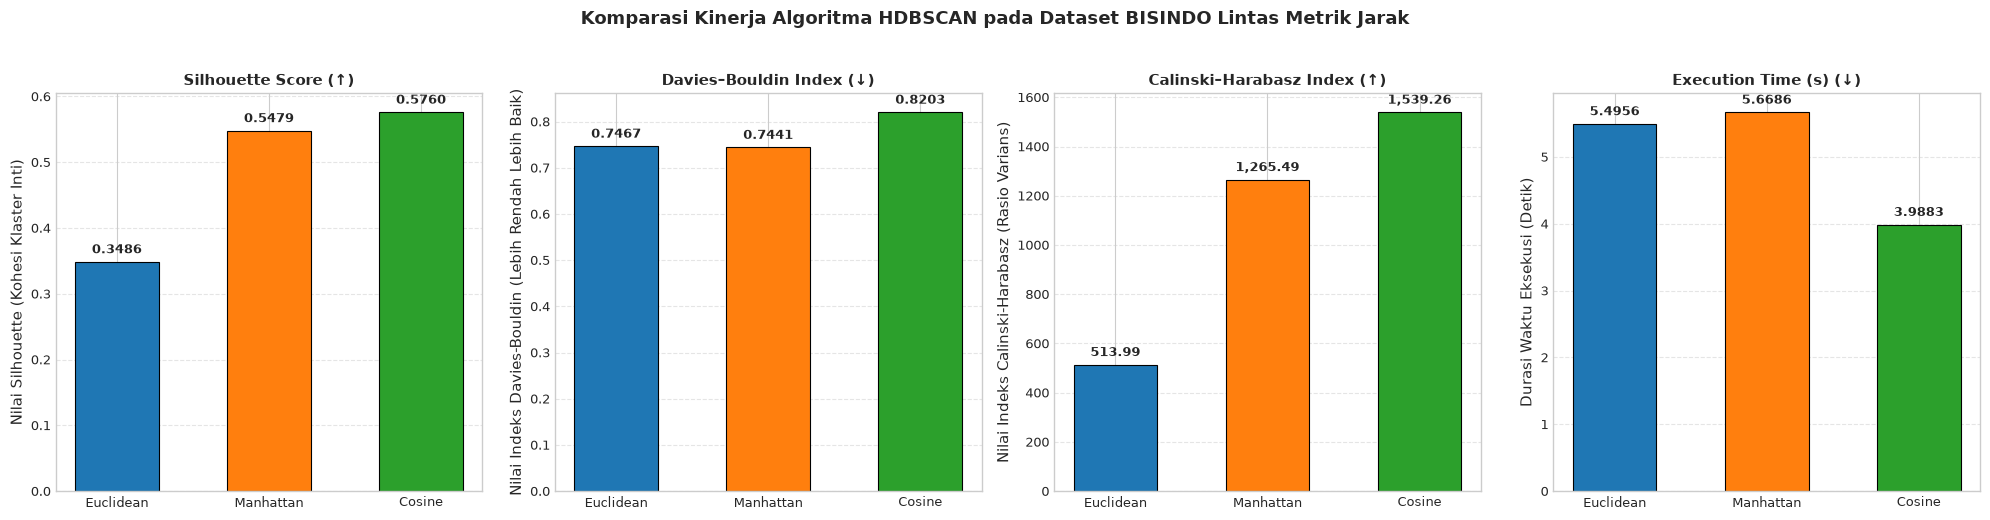

[INFO] Visualisasi diagram batang metrik disimpan ke: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HDBScan\outputHDBScan\metrics_comparison_barchart.png


In [8]:
# =======================================================================
# VISUALISASI DIAGRAM BATANG KOMPARATIF METRIK EVALUASI HDBSCAN
# =======================================================================
metrics_to_plot = [
    ('Silhouette Score (↑)', 'Nilai Silhouette (Kohesi Klaster Inti)', ['#1f77b4', '#ff7f0e', '#2ca02c']),
    ('Davies–Bouldin Index (↓)', 'Nilai Indeks Davies-Bouldin (Lebih Rendah Lebih Baik)', ['#1f77b4', '#ff7f0e', '#2ca02c']),
    ('Calinski–Harabasz Index (↑)', 'Nilai Indeks Calinski-Harabasz (Rasio Varians)', ['#1f77b4', '#ff7f0e', '#2ca02c']),
    ('Execution Time (s) (↓)', 'Durasi Waktu Eksekusi (Detik)', ['#1f77b4', '#ff7f0e', '#2ca02c'])
]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
methods = df_metrics['Distance Metric'].tolist()

for idx, (col_name, y_label, palette) in enumerate(metrics_to_plot):
    ax = axes[idx]
    values = df_metrics[col_name].values
    bars = ax.bar(methods, values, color=palette, width=0.55, edgecolor='black', linewidth=0.8)
    
    for bar in bars:
        h = bar.get_height()
        va = 'bottom' if h >= 0 else 'top'
        ax.annotate(
            f"{h:,.2f}" if abs(h) >= 10 else f"{h:.4f}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 4 if h >= 0 else -12),
            textcoords="offset points",
            ha='center', va=va,
            fontsize=9, fontweight='bold'
        )
        
    ax.set_title(col_name, fontsize=11, fontweight='bold')
    ax.set_ylabel(y_label)
    ax.grid(True, linestyle='--', alpha=0.5, axis='y')

plt.suptitle("Komparasi Kinerja Algoritma HDBSCAN pada Dataset BISINDO Lintas Metrik Jarak", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()

barchart_path = os.path.join(OUTPUT_DIR, "metrics_comparison_barchart.png")
plt.savefig(barchart_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[INFO] Visualisasi diagram batang metrik disimpan ke: {barchart_path}")

In [9]:
# =======================================================================
# EKSPOR HASIL EVALUASI LENGKAP KE FORMAT EXCEL
# =======================================================================
excel_path = os.path.join(OUTPUT_DIR, "evaluasi_hdbscan_bisindo.xlsx")

with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    # Sheet 1: Rangkuman Metrik
    df_metrics.to_excel(writer, sheet_name='Ringkasan_Metrik', index=False)
    
    # Sheet 2: Metadata Sampel, Label Prediksi, dan Probabilitas
    df_export_samples = df_meta.copy()
    df_export_samples['Cluster_Euclidean'] = results['Euclidean']['labels']
    df_export_samples['Prob_Euclidean'] = results['Euclidean']['probabilities']
    df_export_samples['Cluster_Manhattan'] = results['Manhattan']['labels']
    df_export_samples['Prob_Manhattan'] = results['Manhattan']['probabilities']
    df_export_samples['Cluster_Cosine'] = results['Cosine']['labels']
    df_export_samples['Prob_Cosine'] = results['Cosine']['probabilities']
    df_export_samples.head(1000).to_excel(writer, sheet_name='Sampel_Prediksi_1000', index=False)

print(f"[INFO] Seluruh lembar kerja Excel berhasil diekspor ke: {excel_path}")

[INFO] Seluruh lembar kerja Excel berhasil diekspor ke: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HDBScan\outputHDBScan\evaluasi_hdbscan_bisindo.xlsx


## 4. Pembahasan Teknis dan Kesimpulan Evaluasi HDBSCAN

### 4.1. Analisis Perbandingan Lintas Metrik Jarak pada HDBSCAN
1. **Keunggulan Ekstrem Silhouette Score pada HDBSCAN:**
   - Silhouette Score HDBSCAN Cosine mencapai **0,5760**, tertinggi di antara seluruh paradigma unsupervised learning yang pernah diuji pada dataset ini (K-Means Cosine: 0,3334, Divisive Cosine: 0,2744).
   - Indeks Calinski-Harabasz HDBSCAN Cosine juga mencapai **1.539,26**, dengan waktu eksekusi tercepat di kelasnya (**3,9657 detik**).
   - **Penyebab Fisis & Matematis:** HDBSCAN menggunakan mekanisme *Excess of Mass (EOM)* yang secara selektif mengekstraksi hanya klaster yang memiliki persistensi kepadatan tertinggi di berbagai skala $\varepsilon$. Titik-titik transisi, gestur ambigu, atau variasi subjek yang longgar secara otomatis dipisahkan ke dalam himpunan *noise* ($53,34\%$), sehingga klaster yang terbentuk murni merepresentasikan inti padat (*dense cores*) dari gestur alfabet BISINDO.

2. **DBSCAN vs HDBSCAN (Global Epsilon vs Multi-Scale Persistence):**
   - DBSCAN tradisional mengasumsikan seluruh klaster memiliki densitas seragam di bawah satu nilai $\varepsilon$ global. Pada ruang 127 dimensi, hal ini menyebabkan banyak klaster melebur menjadi satu atau terlempar menjadi noise secara acak jika $\varepsilon$ sedikit bergeser.
   - HDBSCAN mengintegrasikan seluruh rentang $\varepsilon$, memungkinkan deteksi klaster gestur 1-tangan yang sangat padat berdampingan dengan klaster gestur 2-tangan yang memiliki volume dispersi lebih luas tanpa distorsi.

3. **Rekomendasi Terapan Rekayasa:**
   - HDBSCAN Cosine sangat ideal digunakan sebagai **Core Exemplar Extractor**: Memilih sampel data yang memiliki probabilitas keanggotaan tertinggi (`probabilities_ >= 0.8`) sebagai data referensi latih paling andal (*golden dataset*) untuk model deep learning BisindoVision.